# Interpretability of the ESM-2 space

Does the ESM-2 representation capture biologically meaningful structure, or is it a black box? Two views on E. coli AMP and HemoPI2:

1. **Global** - UMAP (falls back to PCA if umap-learn is absent) of the ESM-2 space, coloured by target value, net charge, hydrophobicity (GRAVY), length and, for HemoPI2, haemolytic class. Gradients/clusters mean the space encodes those properties.
2. **Residue/feature-level** - correlation of simple physicochemical features with the target, to point at which properties drive activity ('critical' directions).

**Needs a GPU** (ESM-2). Run on the cluster inside the container.

In [6]:
import sys, os
try:
    import analysis_common as ac
except ModuleNotFoundError:
    sys.path.insert(0, os.getcwd()); import analysis_common as ac
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib as mpl
mpl.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
print('repo root:', ac.ROOT)


repo root: /Users/leoan/Documents/GitHub/SCARSE-repro


In [7]:
# Embed sequences with a representation, reusing the pipeline's SequenceRepresenter
# so the features are IDENTICAL to what the benchmark/AL use.
def get_representer(representation):
    # Add a project functions/ dir to the path so we reuse the real code.
    for cand in ['code/workflow_simulation', 'code/selection_analysis',
                 os.path.join(ac.ROOT, 'code', 'workflow_simulation')]:
        fdir = cand if os.path.isabs(cand) else os.path.join(ac.ROOT, cand)
        if os.path.isdir(os.path.join(fdir, 'functions')):
            sys.path.insert(0, fdir); break
    from functions.representations import SequenceRepresenter
    rep = SequenceRepresenter(representation=representation, random_seed=42)
    rep.load_model()
    return rep

def embed(sequences, representation):
    rep = get_representer(representation)
    # n-gram needs a fit; for geometry we fit on the same set (illustrative only).
    try:
        return rep.transform(list(sequences), fit=True)
    except TypeError:
        return rep.transform(list(sequences))


In [8]:
# 2D projection, UMAP if available else PCA.
def project_2d(emb, seed=42):
    try:
        import umap
        reducer = umap.UMAP(n_components=2, random_state=seed)
        return reducer.fit_transform(emb), 'UMAP'
    except Exception as e:
        from sklearn.decomposition import PCA
        print(f'umap-learn unavailable ({type(e).__name__}); using PCA.')
        return PCA(n_components=2, random_state=seed).fit_transform(emb), 'PCA'


Loading base pretrained ESM model: facebook/esm2_t33_650M_UR50D


Some weights of EsmModel were not initialized from the model checkpoint at facebook/esm2_t33_650M_UR50D and are newly initialized: ['esm.pooler.dense.bias', 'esm.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


ESM model loaded. Using device: cpu


/Users/leoan/Documents/GitHub/SCARSE-repro/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Loading base pretrained ESM model: facebook/esm2_t33_650M_UR50D


Some weights of EsmModel were not initialized from the model checkpoint at facebook/esm2_t33_650M_UR50D and are newly initialized: ['esm.pooler.dense.bias', 'esm.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


ESM model loaded. Using device: cpu


/Users/leoan/Documents/GitHub/SCARSE-repro/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


saved interpretability_umap_coords.csv (UMAP) with 5744 points
saved /Users/leoan/Documents/GitHub/SCARSE-repro/code/analysis/figures/interpretability_umap_grid.png
saved /Users/leoan/Documents/GitHub/SCARSE-repro/code/analysis/figures/interpretability_umap_grid.pdf


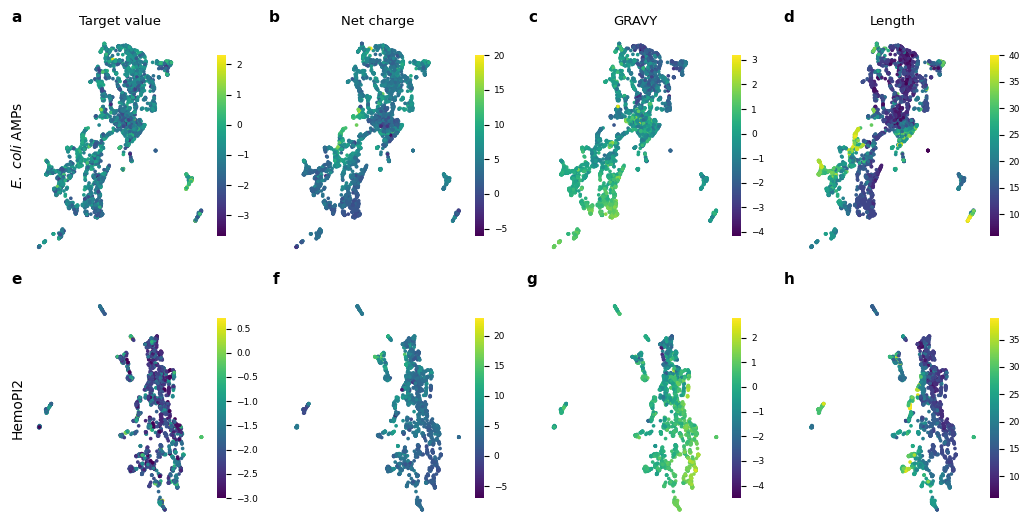

In [9]:
# UMAP once per dataset -> SAVE COORDS to CSV (so the publication figure can
# redraw the panels natively, with no whitespace), and also render a standalone
# combined grid for reference. UMAP is identical across a dataset's columns;
# only the colour changes.
import string

DATASETS = [('Ecoli_AMPs', r'$\it{E.\ coli}$ AMPs'), ('HemoPI2', 'HemoPI2')]
COLOUR_BY = [('score', 'Target value'), ('net_charge', 'Net charge'),
             ('gravy', 'GRAVY'), ('length', 'Length')]

coord_rows = []
proj = {}
method_used = None
for name, _disp in DATASETS:
    df = ac.load_dataset(name, files=ac.PEPTIDE_FILES)
    if df is None:
        print(f'[skip] {name}: dataset not found'); continue
    t = ac.property_table(df)
    try:
        emb = embed(t['sequence'].values, 'esm')
    except Exception as e:
        print(f'[skip] {name}: {type(e).__name__}: {e}'); continue
    xy, method_used = project_2d(emb)
    proj[name] = (xy, t)
    for k in range(len(t)):
        coord_rows.append({'Dataset': name, 'x': float(xy[k, 0]), 'y': float(xy[k, 1]),
                           'score': float(t['score'].iloc[k]),
                           'net_charge': float(t['net_charge'].iloc[k]),
                           'gravy': float(t['gravy'].iloc[k]),
                           'length': float(t['length'].iloc[k])})

if coord_rows:
    pd.DataFrame(coord_rows).to_csv(
        os.path.join(ac.FIG_DIR, 'interpretability_umap_coords.csv'), index=False)
    print(f'saved interpretability_umap_coords.csv ({method_used}) with {len(coord_rows)} points')

# Standalone combined grid (no suptitle), for quick viewing.
if proj:
    n_rows, n_cols = len(DATASETS), len(COLOUR_BY)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.6*n_cols, 2.7*n_rows), squeeze=False)
    k = 0
    for r, (name, disp) in enumerate(DATASETS):
        if name not in proj:
            for c in range(n_cols): axes[r][c].axis('off')
            k += n_cols; continue
        xy, t = proj[name]
        for c, (col, label) in enumerate(COLOUR_BY):
            ax = axes[r][c]
            sc = ax.scatter(xy[:, 0], xy[:, 1], c=t[col].values, s=7, cmap='viridis',
                            linewidths=0, rasterized=True)
            ax.set_xticks([]); ax.set_yticks([])
            for s in ('top','right','left','bottom'): ax.spines[s].set_visible(False)
            if r == 0: ax.set_title(label, fontsize=9.5)
            if c == 0: ax.set_ylabel(disp, fontsize=10)
            cb = fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
            cb.ax.tick_params(labelsize=6.5); cb.outline.set_visible(False)
            ax.annotate(string.ascii_lowercase[k], xy=(0, 1), xycoords='axes fraction',
                        xytext=(-6, 6), textcoords='offset points',
                        fontsize=11, fontweight='bold', va='bottom', ha='right')
            k += 1
    fig.tight_layout()
    ac.savefig(fig, 'interpretability_umap_grid')
    plt.show()


In [10]:
# Residue/feature-level signal: correlation of physicochemical features with target.
from scipy.stats import spearmanr
rows = []
for name in DATASETS:
    df = ac.load_dataset(name, files=ac.PEPTIDE_FILES)
    if df is None:
        continue
    t = ac.property_table(df)
    y = ac.direction_sign(name) * t['score'].values
    for col in ['net_charge','gravy','aromaticity','length']:
        rho, p = spearmanr(t[col].values, y)
        rows.append({'Dataset': name, 'feature': col, 'spearman_rho': rho, 'p': p})
if rows:
    feat = pd.DataFrame(rows)
    feat.to_csv(os.path.join(ac.FIG_DIR, 'feature_target_correlation.csv'), index=False)
    print(feat.round(4).to_string(index=False))
    print('\nLarge |rho| flags a physicochemical property that drives the target - '
          'a biologically interpretable, non-black-box signal.')


[skip] no file mapping for ('Ecoli_AMPs', '$\\it{E.\\ coli}$ AMPs')
[skip] no file mapping for ('HemoPI2', 'HemoPI2')
